
# RQ25 — Final generalization-regime synthesis

## Scientific question

**What generalization regimes emerge from the completed PhageLysClass benchmark once task formulation, R×S geometry, robustness, stepwise degradation, evidence quantity/structure, PU behavior, uncertainty, compute, deployment selection, ensembles, and the frozen product architecture are considered jointly?**

This notebook replaces the premature `20_RQ20_final_generalization_regime_synthesis_v2` template with the canonical **RQ25** synthesis.

RQ25 does **not** train models, regenerate predictions, rerun bootstrap, optimize ensembles, or reopen the frozen RQ26–RQ28 decisions. Its role is to integrate the already-completed evidence into:

1. a final **generalization-regime catalogue** for the seven benchmark tasks;
2. a cross-cutting map of the mechanisms that shape generalization;
3. the final connection between benchmark regimes and the frozen PhageLysClass deployment architecture;
4. manuscript-ready quantitative claims and guardrails.

### Newly integrated evidence

The old synthesis template predated several analyses that materially change the interpretation. The final RQ25 therefore incorporates explicitly:

- **RQ6** — complete R×S surface geometry;
- **RQ17** — multidimensional robustness / what “winning” means;
- **RQ20** — stepwise 90→70→50→30 degradation timing;
- **RQ21** — joint R×S trajectories and asymmetric strictness allocation;
- **RQ22** — evidence quantity and evidence structure;
- **RQ26** — evidence-adaptive individual deployment portfolios;
- **RQ27** — ensemble gain and error complementarity;
- **RQ28** — final `2 core + 3 auxiliary` PhageLysClass architecture.

RQ29 end-to-end inference validation is intentionally **not** required to answer RQ25. RQ25 freezes the scientific regime synthesis; RQ29 validates the final operational inference path.



## Interpretation contract

The synthesis obeys the following guardrails.

- `R` and `S` are different protocol factors:
  - `R` changes the available sequence universe, redundancy, and evidence quantity/structure;
  - `S` primarily reorganizes train–test homology topology at approximately fixed gross sample size.
- Native-test R/S contrasts remain the primary benchmark observations. Common-test analyses are sensitivity analyses.
- Joint R×S strictness is **directional**, not a one-dimensional scalar difficulty variable.
- RQ22 is descriptive: evidence quantity/structure can be statistically aligned with R-associated degradation without establishing causal mediation.
- RQ17 robustness is multidimensional; peak, mean, worst-case, regret, rank, R/S sensitivity, and interaction need not identify the same winner.
- Bootstrap intervals quantify finite-test uncertainty conditional on fitted models; overlap with zero is not evidence of equivalence.
- `≤0.02 MCC` is a descriptive deployment-competitiveness band, not a statistical equivalence margin.
- `U` is unlabeled, never a confirmed negative class.
- PU known-positive recovery and PU candidate discovery are distinct objectives.
- PU runtime remains not estimable if instrumentation is absent.
- Candidate prioritization identifies proteins for experimental characterization, not computationally validated enzymes.
- RQ26/RQ27 are retrospective post-benchmark deployment analyses.
- RQ28 freezes **recipes and architecture**, not final refitted production weights.
- VAL remains evidence-limited and must retain explicit uncertainty/support guardrails.


In [1]:

from pathlib import Path
import json
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 500)
pd.set_option("display.width", 300)
pd.set_option("display.max_rows", 500)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

TASK_ORDER = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
    "multiclass_clean",
]

TASK_LABEL = {
    "global_easy": "Global easy",
    "global_hard": "Global hard",
    "global_mixed": "Global mixed",
    "subtype_endolysin": "Endolysin",
    "subtype_depolymerase": "Depolymerase",
    "subtype_val": "VAL",
    "multiclass_clean": "Multiclass",
}

REP_ORDER = [
    "roxy_48",
    "onehot_1024",
    "esm2_t6_8m",
    "esm2_t30_150m",
]

ALG_ORDER = ["KNN", "LR", "MLP", "RF", "XGB"]

T30 = "esm2_t30_150m"
T6 = "esm2_t6_8m"
DEPLOYMENT_NEAR_BEST_MCC = 0.02


def find_project_root(start=None):
    explicit = os.environ.get("PHAGELYSCLASS_ROOT")
    if explicit:
        root = Path(explicit).expanduser().resolve()
        if (
            (root / "results/analysis_supervised/stage12a/supervised_master_results.tsv").is_file()
            and (root / "results/analysis_supervised/notebook_cache/rq6_surface_geometry/rq6_surface_cells.tsv").is_file()
            and (root / "results/analysis_deployment/rq28/rq28_frozen_components.tsv").is_file()
        ):
            return root
        raise FileNotFoundError(
            f"PHAGELYSCLASS_ROOT does not satisfy the final RQ25 contract: {root}"
        )

    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a/supervised_master_results.tsv").is_file()
            and (candidate / "results/analysis_supervised/notebook_cache/rq6_surface_geometry/rq6_surface_cells.tsv").is_file()
            and (candidate / "results/analysis_deployment/rq28/rq28_frozen_components.tsv").is_file()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate PhageLysClass project root with Stage12A, RQ6, and RQ28 outputs."
    )


ROOT = find_project_root()

SUP_STAGE12A = ROOT / "results/analysis_supervised/stage12a"
SUP_CACHE = ROOT / "results/analysis_supervised/notebook_cache"
PU_CACHE = ROOT / "results/analysis_pu/notebook_cache"
BOOT_CACHE = ROOT / "results/analysis_bootstrap/rq17"   # legacy path: scientific RQ19
COMPUTE_CACHE = ROOT / "results/analysis_compute/rq18"  # legacy path: scientific RQ23
CANDIDATE_CACHE = ROOT / "results/analysis_candidates/rq19_final"  # legacy path: scientific RQ24

RQ26_DIR = ROOT / "results/analysis_deployment/rq26"
RQ27_DIR = ROOT / "results/analysis_deployment/rq27"
RQ28_DIR = ROOT / "results/analysis_deployment/rq28"

RQ25_OUT = ROOT / "results/analysis_synthesis/rq25"
FIG_DIR = RQ25_OUT / "figures"
RQ25_OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RQ25_OUT:", RQ25_OUT)
print("No training, prediction regeneration, bootstrap, or deployment reselection is performed.")


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
RQ25_OUT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_synthesis/rq25
No training, prediction regeneration, bootstrap, or deployment reselection is performed.


## 1. Real-project preflight

In [2]:

PATHS = {
    # Frozen benchmark / early regime map.
    "supervised_master": SUP_STAGE12A / "supervised_master_results.tsv",
    "rq6_surface_cells": SUP_CACHE / "rq6_surface_geometry/rq6_surface_cells.tsv",
    "rq9_fingerprint": SUP_CACHE / "rq9_functional_regime_fingerprint.tsv",

    # Scientific RQ17 robustness.
    "rq17_robustness": SUP_CACHE / "rq17_robustness_synthesis/rq17_surface_robustness_profiles.tsv",

    # Scientific RQ20.
    "rq20_sup_step_summary": SUP_CACHE / "rq20_stepwise_regimes/rq20_supervised_step_summary.tsv",
    "rq20_sup_trajectories": SUP_CACHE / "rq20_stepwise_regimes/rq20_supervised_trajectory_regimes.tsv",
    "rq20_pu_step_summary": SUP_CACHE / "rq20_stepwise_regimes/rq20_PU_step_summary.tsv",
    "rq20_pu_trajectories": SUP_CACHE / "rq20_stepwise_regimes/rq20_PU_trajectory_regimes.tsv",

    # Scientific RQ21.
    "rq21_profiles": SUP_CACHE / "rq21_joint_RxS_trajectories/rq21_surface_mixed_trajectory_profiles.tsv",

    # Scientific RQ22.
    "rq22_evidence": SUP_CACHE / "rq22_evidence_quantity_structure/rq22_evidence_cell_state.tsv",
    "rq22_nested": SUP_CACHE / "rq22_evidence_quantity_structure/rq22_nested_unique_cell_models.tsv",
    "rq22_residual_surface": SUP_CACHE / "rq22_evidence_quantity_structure/rq22_surface_residual_R.tsv",
    "rq22_residual_task": SUP_CACHE / "rq22_evidence_quantity_structure/rq22_residual_R_by_task.tsv",
    "rq22_residual_rep": SUP_CACHE / "rq22_evidence_quantity_structure/rq22_residual_R_by_representation.tsv",
    "rq22_binary_support": SUP_CACHE / "rq22_evidence_quantity_structure/rq22_binary_support_summary.tsv",

    # Finite-test uncertainty / common-test sensitivity summaries.
    "bootstrap_representation": BOOT_CACHE / "rq17_supervised_representation_uncertainty_summary.tsv",
    "bootstrap_algorithm": BOOT_CACHE / "rq17_supervised_algorithm_uncertainty_summary.tsv",
    "bootstrap_commonS": BOOT_CACHE / "rq17_commonS_uncertainty_by_task_R.tsv",
    "bootstrap_commonR": BOOT_CACHE / "rq17_commonR_T30_uncertainty_by_S.tsv",
    "bootstrap_VAL": BOOT_CACHE / "rq17_VAL_uncertainty_summary.tsv",

    # PU.
    "pu_native": PU_CACHE / "rq12_pu_native_score_diagnostics.tsv",
    "pu_rep_method": PU_CACHE / "rq15_evidence_summary.tsv",

    # Scientific RQ23 compute.
    "compute_cells": COMPUTE_CACHE / "rq18_supervised_efficiency_cells.tsv",

    # Scientific RQ24 candidate prioritization.
    "candidate_summary": CANDIDATE_CACHE / "rq19_final_summary.tsv",
    "candidate_top20": CANDIDATE_CACHE / "rq19_final_top20_evidence_panel.tsv",

    # RQ26–RQ28 deployment.
    "rq26_topK": RQ26_DIR / "rq26_topK_individual_candidates.tsv",
    "rq27_task_answer": RQ27_DIR / "rq27_task_answer.tsv",
    "rq27_ensemble_vs_single": RQ27_DIR / "rq27_ensemble_vs_individual.tsv",
    "rq27_weighted_summary": RQ27_DIR / "rq27_weighted_vs_unweighted_summary.tsv",
    "rq27_complementarity": RQ27_DIR / "rq27_task_complementarity_summary.tsv",
    "rq28_frozen_components": RQ28_DIR / "rq28_frozen_components.tsv",
    "rq28_architecture": RQ28_DIR / "rq28_architecture_comparison.tsv",
    "rq28_architecture_json": RQ28_DIR / "rq28_production_architecture.json",
}

preflight = pd.DataFrame([
    {
        "artifact": name,
        "path": str(path),
        "exists": path.is_file(),
    }
    for name, path in PATHS.items()
])

display(preflight)

missing = preflight[~preflight["exists"]]
if len(missing):
    raise FileNotFoundError(
        "RQ25 cannot synthesize the completed benchmark because required artifacts are missing:\n"
        + missing[["artifact", "path"]].to_string(index=False)
    )

print("REAL_PROJECT_PREFLIGHT_OK")


,artifact,path,exists
0,supervised_master,/home/david/Desktop/colabs/inta_project/phagel...,True
1,rq6_surface_cells,/home/david/Desktop/colabs/inta_project/phagel...,True
2,rq9_fingerprint,/home/david/Desktop/colabs/inta_project/phagel...,True
3,rq17_robustness,/home/david/Desktop/colabs/inta_project/phagel...,True
4,rq20_sup_step_summary,/home/david/Desktop/colabs/inta_project/phagel...,True
5,rq20_sup_trajectories,/home/david/Desktop/colabs/inta_project/phagel...,True
6,rq20_pu_step_summary,/home/david/Desktop/colabs/inta_project/phagel...,True
7,rq20_pu_trajectories,/home/david/Desktop/colabs/inta_project/phagel...,True
8,rq21_profiles,/home/david/Desktop/colabs/inta_project/phagel...,True
9,rq22_evidence,/home/david/Desktop/colabs/inta_project/phagel...,True


REAL_PROJECT_PREFLIGHT_OK


## 2. Load and validate frozen evidence

In [3]:

def read_tsv(name):
    return pd.read_csv(PATHS[name], sep="\t", low_memory=False)

sup = read_tsv("supervised_master")
rq6 = read_tsv("rq6_surface_cells")
rq9 = read_tsv("rq9_fingerprint")
robust = read_tsv("rq17_robustness")
sup_steps = read_tsv("rq20_sup_step_summary")
sup_trajectories = read_tsv("rq20_sup_trajectories")
pu_steps = read_tsv("rq20_pu_step_summary")
pu_trajectories = read_tsv("rq20_pu_trajectories")
joint = read_tsv("rq21_profiles")
evidence = read_tsv("rq22_evidence")
nested = read_tsv("rq22_nested")
residual_surface = read_tsv("rq22_residual_surface")
residual_task = read_tsv("rq22_residual_task")
residual_rep = read_tsv("rq22_residual_rep")
binary_support = read_tsv("rq22_binary_support")

rep_unc = read_tsv("bootstrap_representation")
alg_unc = read_tsv("bootstrap_algorithm")
commonS_unc = read_tsv("bootstrap_commonS")
commonR_unc = read_tsv("bootstrap_commonR")
val_unc = read_tsv("bootstrap_VAL")

pu_native = read_tsv("pu_native")
pu_rep_method = read_tsv("pu_rep_method")
compute = read_tsv("compute_cells")
candidate_summary = read_tsv("candidate_summary")
candidate_top20 = read_tsv("candidate_top20")

topk = read_tsv("rq26_topK")
rq27_task = read_tsv("rq27_task_answer")
rq27_ensemble = read_tsv("rq27_ensemble_vs_single")
rq27_weighted = read_tsv("rq27_weighted_summary")
rq27_complementarity = read_tsv("rq27_complementarity")
frozen_components = read_tsv("rq28_frozen_components")
architecture = read_tsv("rq28_architecture")
architecture_json = json.loads(PATHS["rq28_architecture_json"].read_text())


def require(df, cols, name):
    missing = set(cols) - set(df.columns)
    if missing:
        raise KeyError(f"{name} missing required columns: {sorted(missing)}")


require(sup, ["task","R","S","representation","algorithm","mcc"], "supervised_master")
require(rq6, ["task","R","S","representation","algorithm","mcc","delta_from_R90S90"], "RQ6")
require(robust, [
    "task","representation","algorithm","mean_mcc","worst_mcc","mean_rank",
    "mean_regret","strict_mcc_R30S30","R_sensitivity_abs_median",
    "S_sensitivity_abs_median","interaction_rms"
], "RQ17 robustness")
require(joint, [
    "task","representation","algorithm","diag_net_delta",
    "strict_retention_fraction","median_same_J_range",
    "median_abs_allocation_delta","fraction_R_heavy_worse",
    "median_joint_excess_over_additive"
], "RQ21")
require(evidence, [
    "task","R","S","n_train","n_test","n_clusters_train",
    "entity_retention_to_R90","cluster_richness_to_R90",
    "train_size_ratio_to_S90","train_cluster_ratio_to_S90",
    "train_density_ratio_to_S90"
], "RQ22 evidence")
require(residual_surface, [
    "task","representation","algorithm","raw_R_effect_abs_median",
    "QS_residual_R_effect_abs_median","QS_residual_fraction"
], "RQ22 residual R")
require(topk, [
    "task","strategy_id","representation","algorithm","mean_mcc",
    "worst_mcc","strict_mcc_R30S30"
], "RQ26")
require(rq27_task, [
    "task","max_mean_gain_vs_best_single","max_worst_gain_vs_best_single",
    "max_strict_gain_vs_best_single"
], "RQ27 task answer")
require(frozen_components, [
    "task","tier","default_execution","option_type","voting_scheme",
    "member_strategy_ids","benchmark_mean_mcc","benchmark_worst_mcc",
    "benchmark_strict_R30S30_mcc"
], "RQ28 frozen components")

assert len(sup) == 2240
assert len(rq6) == 2240
assert len(robust) == 140
assert len(joint) == 140
assert len(evidence) == 112
assert len(residual_surface) == 140
assert set(sup["task"]) == set(TASK_ORDER)
assert sup.groupby(["task","representation","algorithm"]).size().eq(16).all()
assert len(frozen_components) == 5

print("Supervised rows:", len(sup))
print("RQ6 surface cells:", len(rq6))
print("RQ17 robustness surfaces:", len(robust))
print("RQ21 joint profiles:", len(joint))
print("RQ22 evidence cells:", len(evidence))
print("RQ26 selected individuals:", len(topk))
print("RQ28 frozen components:", len(frozen_components))
print("UPSTREAM_SCHEMA_OK")


Supervised rows: 2240
RQ6 surface cells: 2240
RQ17 robustness surfaces: 140
RQ21 joint profiles: 140
RQ22 evidence cells: 112
RQ26 selected individuals: 23
RQ28 frozen components: 5
UPSTREAM_SCHEMA_OK


# Part I — Geometry of generalization

## 3. RQ6: complete R×S geometry and task-level effect backbone

In [4]:

# Extreme native-test effects, computed from the canonical RQ6 surface cells.
task_geometry_rows = []

for task, grp in rq6.groupby("task", sort=False):
    surface_vals = grp["mcc"].astype(float)

    # Extreme R effect: R30 - R90 at fixed S, then median across S/model families.
    R_effects = []
    for (rep, alg, s), g in grp.groupby(["representation","algorithm","S"]):
        x = g.set_index("R")["mcc"]
        if {90,30} <= set(x.index):
            R_effects.append(float(x.loc[30] - x.loc[90]))

    # Extreme S effect: S30 - S90 at fixed R.
    S_effects = []
    for (rep, alg, r), g in grp.groupby(["representation","algorithm","R"]):
        x = g.set_index("S")["mcc"]
        if {90,30} <= set(x.index):
            S_effects.append(float(x.loc[30] - x.loc[90]))

    # Matched T30 - T6.
    piv = grp.pivot_table(
        index=["R","S","algorithm"],
        columns="representation",
        values="mcc",
        aggfunc="first",
    )
    t30_t6 = (
        piv[T30] - piv[T6]
        if {T30,T6} <= set(piv.columns)
        else pd.Series(dtype=float)
    )

    permissive = grp[grp["R"].eq(90) & grp["S"].eq(90)]["mcc"]
    strict = grp[grp["R"].eq(30) & grp["S"].eq(30)]["mcc"]

    task_geometry_rows.append({
        "task": task,
        "overall_median_mcc": float(surface_vals.median()),
        "permissive_R90S90_median_mcc": float(permissive.median()),
        "strict_R30S30_median_mcc": float(strict.median()),
        "median_R30_minus_R90": float(np.median(R_effects)),
        "median_S30_minus_S90": float(np.median(S_effects)),
        "median_abs_R_effect": float(np.median(np.abs(R_effects))),
        "median_abs_S_effect": float(np.median(np.abs(S_effects))),
        "median_T30_minus_T6": float(t30_t6.median()),
        "surface_cell_range": float(surface_vals.max() - surface_vals.min()),
    })

task_geometry = pd.DataFrame(task_geometry_rows)
task_geometry["R_to_S_abs_ratio"] = (
    task_geometry["median_abs_R_effect"]
    / task_geometry["median_abs_S_effect"].replace(0, np.nan)
)

display(task_geometry.set_index("task").reindex(TASK_ORDER))
print("RQ6_GEOMETRY_SYNTHESIS_OK")


,overall_median_mcc,permissive_R90S90_median_mcc,strict_R30S30_median_mcc,median_R30_minus_R90,median_S30_minus_S90,median_abs_R_effect,median_abs_S_effect,median_T30_minus_T6,surface_cell_range,R_to_S_abs_ratio
task,,,,,,,,,,
global_easy,0.715267,0.774564,0.664537,-0.102103,-0.017895,0.102103,0.018622,0.113017,0.852251,5.482884
global_hard,0.896734,0.939674,0.873673,-0.045614,-0.007104,0.045614,0.012490,0.007816,0.298337,3.652000
global_mixed,0.721355,0.783495,0.648663,-0.103402,-0.023472,0.103402,0.023472,0.104026,0.864615,4.405273
subtype_endolysin,0.697403,0.774572,0.590197,-0.142878,-0.019415,0.142878,0.027656,0.133600,0.962785,5.166216
subtype_depolymerase,0.840849,0.868501,0.849102,0.018144,-0.007922,0.037814,0.021504,0.021048,0.962101,1.758467
subtype_val,0.483795,0.714356,0.406358,-0.044254,-0.035334,0.111745,0.077636,0.121127,0.926850,1.439351
multiclass_clean,0.811130,0.840622,0.820753,-0.022622,-0.019777,0.030760,0.025002,0.030146,0.457759,1.230310


RQ6_GEOMETRY_SYNTHESIS_OK


## 4. RQ17: robustness is multidimensional

In [5]:

robustness_rows = []

for task, grp in robust.groupby("task", sort=False):
    best_mean = grp.sort_values(
        ["mean_mcc","worst_mcc"], ascending=[False,False]
    ).iloc[0]
    best_worst = grp.sort_values(
        ["worst_mcc","mean_mcc"], ascending=[False,False]
    ).iloc[0]
    best_rank = grp.sort_values(
        ["mean_rank","mean_regret","mean_mcc"], ascending=[True,True,False]
    ).iloc[0]
    best_regret = grp.sort_values(
        ["mean_regret","mean_rank","mean_mcc"], ascending=[True,True,False]
    ).iloc[0]
    best_strict = grp.sort_values(
        ["strict_mcc_R30S30","mean_mcc"], ascending=[False,False]
    ).iloc[0]

    winners = {
        f"{best_mean['representation']}+{best_mean['algorithm']}",
        f"{best_worst['representation']}+{best_worst['algorithm']}",
        f"{best_rank['representation']}+{best_rank['algorithm']}",
        f"{best_regret['representation']}+{best_regret['algorithm']}",
        f"{best_strict['representation']}+{best_strict['algorithm']}",
    }

    robustness_rows.append({
        "task": task,
        "n_distinct_winners_across_5_core_criteria": len(winners),
        "performance_leader": f"{best_mean['representation']} + {best_mean['algorithm']}",
        "worst_case_leader": f"{best_worst['representation']} + {best_worst['algorithm']}",
        "rank_consistency_leader": f"{best_rank['representation']} + {best_rank['algorithm']}",
        "lowest_regret_leader": f"{best_regret['representation']} + {best_regret['algorithm']}",
        "strict_leader": f"{best_strict['representation']} + {best_strict['algorithm']}",
        "best_mean_mcc": float(best_mean["mean_mcc"]),
        "best_worst_mcc": float(best_worst["worst_mcc"]),
    })

robustness_synthesis = pd.DataFrame(robustness_rows)
display(robustness_synthesis.set_index("task").reindex(TASK_ORDER))

cross_strategy = (
    robust.groupby(["representation","algorithm"], as_index=False)
    .agg(
        median_mean_mcc=("mean_mcc","median"),
        median_worst_mcc=("worst_mcc","median"),
        median_mean_rank=("mean_rank","median"),
        median_mean_regret=("mean_regret","median"),
        median_R_sensitivity=("R_sensitivity_abs_median","median"),
        median_S_sensitivity=("S_sensitivity_abs_median","median"),
    )
    .sort_values(["median_mean_mcc","median_worst_mcc"], ascending=[False,False])
)
display(cross_strategy.head(10))

print("RQ17_ROBUSTNESS_SYNTHESIS_OK")


,n_distinct_winners_across_5_core_criteria,performance_leader,worst_case_leader,rank_consistency_leader,lowest_regret_leader,strict_leader,best_mean_mcc,best_worst_mcc
task,,,,,,,,
global_easy,1,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + KNN,0.928306,0.883696
global_hard,1,esm2_t30_150m + RF,esm2_t30_150m + RF,esm2_t30_150m + RF,esm2_t30_150m + RF,esm2_t30_150m + RF,0.939007,0.915296
global_mixed,2,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + MLP,0.923514,0.873647
subtype_endolysin,2,esm2_t30_150m + KNN,esm2_t30_150m + XGB,esm2_t30_150m + KNN,esm2_t30_150m + KNN,esm2_t30_150m + KNN,0.922259,0.863086
subtype_depolymerase,2,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + KNN,0.919885,0.885865
subtype_val,2,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + MLP,esm2_t30_150m + LR,0.857846,0.754994
multiclass_clean,3,esm2_t30_150m + MLP,esm2_t30_150m + XGB,esm2_t30_150m + KNN,esm2_t30_150m + MLP,esm2_t30_150m + MLP,0.887182,0.836876


,representation,algorithm,median_mean_mcc,median_worst_mcc,median_mean_rank,median_mean_regret,median_R_sensitivity,median_S_sensitivity
0,esm2_t30_150m,KNN,0.922259,0.859939,2.3750,0.010394,0.062305,0.020051
2,esm2_t30_150m,MLP,0.920808,0.864446,2.0000,0.006059,0.049656,0.010366
4,esm2_t30_150m,XGB,0.916379,0.863086,3.0625,0.011238,0.072177,0.014084
3,esm2_t30_150m,RF,0.878668,0.805241,4.6875,0.047478,0.091676,0.018059
1,esm2_t30_150m,LR,0.875262,0.826977,4.7500,0.041086,0.054312,0.018337
7,esm2_t6_8m,MLP,0.838467,0.760891,6.0625,0.088906,0.101580,0.020644
9,esm2_t6_8m,XGB,0.826531,0.769239,6.5000,0.099951,0.098084,0.018744
5,esm2_t6_8m,KNN,0.820983,0.751080,7.1875,0.105767,0.102023,0.028026
8,esm2_t6_8m,RF,0.760026,0.693228,9.0000,0.168370,0.109107,0.019457
6,esm2_t6_8m,LR,0.730356,0.675837,9.9375,0.200290,0.083529,0.019387


RQ17_ROBUSTNESS_SYNTHESIS_OK


## 5. RQ20: stepwise degradation and absence of a universal breakpoint

In [6]:

# Keep the canonical RQ20 summaries intact.
display(sup_steps)
display(pu_steps)

require(sup_trajectories, ["axis","regime"], "RQ20 supervised trajectories")
require(pu_trajectories, ["axis","regime"], "RQ20 PU trajectories")

sup_regime_composition = (
    sup_trajectories.groupby(["axis","regime"])
    .size()
    .rename("n")
    .reset_index()
)
sup_regime_composition["fraction"] = (
    sup_regime_composition["n"]
    / sup_regime_composition.groupby("axis")["n"].transform("sum")
)

pu_regime_composition = (
    pu_trajectories.groupby(["axis","regime"])
    .size()
    .rename("n")
    .reset_index()
)
pu_regime_composition["fraction"] = (
    pu_regime_composition["n"]
    / pu_regime_composition.groupby("axis")["n"].transform("sum")
)

display(sup_regime_composition)
display(pu_regime_composition)

# Largest concentration of degradative timing is deliberately descriptive.
degradative_labels = {
    "early_degradation","mid_degradation","late_degradation"
}
timing_concentration = (
    sup_regime_composition[
        sup_regime_composition["regime"].isin(degradative_labels)
    ]
    .groupby("axis", as_index=False)
    .agg(max_degradative_fraction=("fraction","max"))
)

display(timing_concentration)
print("RQ20_STEPWISE_SYNTHESIS_OK")


,axis,timing,step,n,mean_delta,median_delta,q25,q75,median_abs_delta,fraction_negative,fraction_positive,fraction_within_tol
0,R,early,R90→R70,560,-0.018252,-0.022014,-0.052118,0.000000,0.034586,0.735714,0.248214,0.083929
1,R,late,R50→R30,560,-0.013584,-0.022173,-0.043332,0.006524,0.031941,0.685714,0.282143,0.083929
2,R,mid,R70→R50,560,-0.041335,-0.023619,-0.049133,0.000000,0.030822,0.725000,0.248214,0.126786
3,S,early,S90→S70,560,-0.006496,-0.001793,-0.016374,0.008816,0.012320,0.535714,0.403571,0.244643
4,S,late,S50→S30,560,-0.016838,-0.008059,-0.031369,0.008180,0.020756,0.633929,0.335714,0.167857
5,S,mid,S70→S50,560,-0.015360,-0.005392,-0.030997,0.007078,0.016938,0.591071,0.380357,0.214286


,axis,timing,step,n,mean_delta,median_delta,q25,q75,median_abs_delta,fraction_negative,fraction_positive,fraction_within_tol
0,R,early,R90→R70,192,-0.031338,-0.025493,-0.041982,-0.013408,0.025493,0.921875,0.078125,0.406250
1,R,late,R50→R30,192,-0.017197,-0.018112,-0.035829,-0.001320,0.024440,0.765625,0.234375,0.411458
2,R,mid,R70→R50,192,-0.025795,-0.028280,-0.041014,-0.007759,0.030531,0.864583,0.135417,0.364583
3,S,early,S90→S70,192,-0.000057,0.001470,-0.012561,0.017169,0.015539,0.494792,0.505208,0.630208
4,S,late,S50→S30,192,-0.011761,-0.009313,-0.025160,-0.000545,0.015147,0.770833,0.229167,0.604167
5,S,mid,S70→S50,192,-0.002071,-0.003032,-0.013358,0.010653,0.012506,0.578125,0.421875,0.677083


,axis,regime,n,fraction
0,R,early_degradation,74,0.132143
1,R,improving,23,0.041071
2,R,late_degradation,138,0.246429
3,R,mid_degradation,70,0.125000
4,R,non_monotonic,249,0.444643
5,R,stable,6,0.010714
6,S,early_degradation,39,0.069643
7,S,improving,31,0.055357
8,S,late_degradation,55,0.098214
9,S,mid_degradation,55,0.098214


,axis,regime,n,fraction
0,R,early_degradation,36,0.187500
1,R,improving,5,0.026042
2,R,late_degradation,51,0.265625
3,R,mid_degradation,61,0.317708
4,R,non_monotonic,28,0.145833
5,R,stable,11,0.057292
6,S,early_degradation,17,0.088542
7,S,improving,14,0.072917
8,S,late_degradation,25,0.130208
9,S,mid_degradation,12,0.062500


,axis,max_degradative_fraction
0,R,0.246429
1,S,0.098214


RQ20_STEPWISE_SYNTHESIS_OK


## 6. RQ21: joint strictness has magnitude and direction

In [7]:

joint_task = (
    joint.groupby("task", as_index=False)
    .agg(
        median_diag_net_delta=("diag_net_delta","median"),
        median_strict_retention=("strict_retention_fraction","median"),
        median_same_J_range=("median_same_J_range","median"),
        median_abs_allocation_delta=("median_abs_allocation_delta","median"),
        fraction_R_heavy_worse=("fraction_R_heavy_worse","mean"),
        median_joint_excess_over_additive=(
            "median_joint_excess_over_additive","median"
        ),
    )
)

joint_global = pd.DataFrame([{
    "median_diag_net_delta": float(joint["diag_net_delta"].median()),
    "median_strict_retention": float(joint["strict_retention_fraction"].median()),
    "median_same_J_range": float(joint["median_same_J_range"].median()),
    "median_abs_allocation_delta": float(joint["median_abs_allocation_delta"].median()),
    "fraction_R_heavy_worse": float(joint["fraction_R_heavy_worse"].mean()),
    "median_joint_excess_over_additive": float(
        joint["median_joint_excess_over_additive"].median()
    ),
}])

display(joint_global)
display(joint_task.set_index("task").reindex(TASK_ORDER))
print("RQ21_JOINT_SYNTHESIS_OK")


,median_diag_net_delta,median_strict_retention,median_same_J_range,median_abs_allocation_delta,fraction_R_heavy_worse,median_joint_excess_over_additive
0,-0.084068,0.90256,0.047034,0.039236,0.670238,0.030824


,median_diag_net_delta,median_strict_retention,median_same_J_range,median_abs_allocation_delta,fraction_R_heavy_worse,median_joint_excess_over_additive
task,,,,,,
global_easy,-0.131290,0.844879,0.054156,0.046441,0.925000,0.029060
global_hard,-0.063979,0.933253,0.032262,0.026699,0.833333,0.016178
global_mixed,-0.126944,0.846554,0.048077,0.040075,0.933333,0.010560
subtype_endolysin,-0.174098,0.801279,0.070516,0.063242,0.950000,0.038931
subtype_depolymerase,0.000493,1.000532,0.034487,0.028283,0.233333,0.027506
subtype_val,-0.194032,0.658388,0.111305,0.092812,0.416667,0.154995
multiclass_clean,-0.030244,0.963631,0.039278,0.031051,0.400000,0.030824


RQ21_JOINT_SYNTHESIS_OK


## 7. RQ22: evidence quantity and topology explain different parts of the landscape

In [8]:

# R-induced evidence attrition at R30 relative to R90.
r30 = evidence[evidence["R"].eq(30)].copy()
s30 = evidence[evidence["S"].eq(30)].copy()

evidence_mechanism_summary = pd.DataFrame([
    {
        "mechanism": "R30_vs_R90",
        "median_train_entity_retention": float(
            r30["entity_retention_to_R90"].median()
        ),
        "median_train_cluster_richness_retention": float(
            r30["cluster_richness_to_R90"].median()
        ),
        "median_train_size_ratio_to_S90": np.nan,
        "median_train_cluster_ratio_to_S90": np.nan,
        "median_train_density_ratio_to_S90": np.nan,
    },
    {
        "mechanism": "S30_vs_S90",
        "median_train_entity_retention": np.nan,
        "median_train_cluster_richness_retention": np.nan,
        "median_train_size_ratio_to_S90": float(
            s30["train_size_ratio_to_S90"].median()
        ),
        "median_train_cluster_ratio_to_S90": float(
            s30["train_cluster_ratio_to_S90"].median()
        ),
        "median_train_density_ratio_to_S90": float(
            s30["train_density_ratio_to_S90"].median()
        ),
    },
])

global_residual_R = pd.DataFrame([{
    "median_raw_abs_R": float(
        residual_surface["raw_R_effect_abs_median"].median()
    ),
    "median_QS_residual_abs_R": float(
        residual_surface["QS_residual_R_effect_abs_median"].median()
    ),
    "median_QS_residual_fraction": float(
        residual_surface["QS_residual_fraction"].median()
    ),
}])

display(evidence_mechanism_summary)
display(global_residual_R)
display(residual_task.set_index("task").reindex(TASK_ORDER))
display(residual_rep)

# Nested model sequence is retained as descriptive evidence, not causal decomposition.
display(nested)
display(binary_support)

print("RQ22_EVIDENCE_SYNTHESIS_OK")


,mechanism,median_train_entity_retention,median_train_cluster_richness_retention,median_train_size_ratio_to_S90,median_train_cluster_ratio_to_S90,median_train_density_ratio_to_S90
0,R30_vs_R90,0.307481,0.5596,NaN,NaN,NaN
1,S30_vs_S90,NaN,NaN,1.000456,0.553651,1.824082


,median_raw_abs_R,median_QS_residual_abs_R,median_QS_residual_fraction
0,0.085105,0.014758,0.195421


,n_surfaces,median_raw_abs_R,median_Q_residual_abs_R,median_QS_residual_abs_R,median_Q_fraction,median_QS_fraction,q25_QS_fraction,q75_QS_fraction
task,,,,,,,,
global_easy,20,0.110931,0.016746,0.010659,0.181443,0.104450,0.075172,0.144366
global_hard,20,0.051388,0.014446,0.011126,0.248795,0.205095,0.108750,0.301844
global_mixed,20,0.109379,0.015987,0.011222,0.146361,0.107572,0.062657,0.155295
subtype_endolysin,20,0.147276,0.023122,0.012844,0.141835,0.084368,0.060206,0.125835
subtype_depolymerase,20,0.040361,0.026231,0.015611,0.887674,0.412092,0.257659,0.651480
subtype_val,20,0.136463,0.114145,0.050249,0.885806,0.400891,0.275684,0.660593
multiclass_clean,20,0.029904,0.020807,0.013638,0.682074,0.482946,0.279983,0.714261


,representation,n_surfaces,median_raw_abs_R,median_Q_residual_abs_R,median_QS_residual_abs_R,median_Q_fraction,median_QS_fraction,q25_QS_fraction,q75_QS_fraction
0,esm2_t30_150m,35,0.062305,0.013165,0.007212,0.183879,0.114389,0.071743,0.397416
1,esm2_t6_8m,35,0.098084,0.019272,0.011569,0.234964,0.198679,0.087651,0.412092
2,onehot_1024,35,0.115912,0.041484,0.020256,0.382472,0.223232,0.128284,0.392452
3,roxy_48,35,0.091551,0.026193,0.017030,0.332337,0.220072,0.131007,0.476921


,model,n,r2,delta_r2_vs_previous,rank,n_columns,rank_deficiency,condition_number
0,M0_task,112,0.803062,NaN,7,7,0,7.872983
1,M1_quantity,112,0.846534,0.043472,8,8,0,9.067064
2,M2_quantity_structure,112,0.865847,0.019312,9,9,0,12.903197
3,M3_quantity_structure_S,112,0.866704,0.000857,12,12,0,15.316655
4,M4_quantity_structure_S_R,112,0.876116,0.009412,15,15,0,136.929560


,task,median_positive_train,min_positive_train,max_positive_train,median_positive_test,min_positive_test,max_positive_test,median_test_prevalence,median_mcc
0,global_easy,2055.5,1106.0,3380.0,884.5,485.0,1479.0,0.162461,0.704959
1,global_hard,2049.0,1123.0,3390.0,882.0,479.0,1469.0,0.691797,0.901506
2,global_mixed,2074.0,1117.0,3384.0,814.0,481.0,1431.0,0.149552,0.695914
3,subtype_depolymerase,276.5,230.0,334.0,116.5,87.0,144.0,0.023301,0.840519
4,subtype_endolysin,1667.5,836.0,2799.0,680.0,362.0,1340.0,0.125597,0.663245
5,subtype_val,47.0,31.0,75.0,18.0,14.0,32.0,0.004430,0.440300


RQ22_EVIDENCE_SYNTHESIS_OK


# Part II — Uncertainty, PU, compute, and deployment consequences

## 8. Finite-test uncertainty and common-test sensitivity

In [9]:

# Compact uncertainty hierarchy. The exact source tables are exported unchanged later.
uncertainty_backbone = pd.DataFrame([
    {
        "contrast_family": "T30_vs_T6",
        "median_point_delta": float(
            rep_unc.loc[
                rep_unc["contrast"].astype(str).str.contains(
                    "T30", case=False, regex=False
                )
                & rep_unc["contrast"].astype(str).str.contains(
                    "T6", case=False, regex=False
                ),
                "median_point_delta",
            ].median()
        ),
        "median_ci_width": float(
            rep_unc.loc[
                rep_unc["contrast"].astype(str).str.contains(
                    "T30", case=False, regex=False
                )
                & rep_unc["contrast"].astype(str).str.contains(
                    "T6", case=False, regex=False
                ),
                "median_ci_width",
            ].median()
        ),
    },
    {
        "contrast_family": "key_algorithm_contrasts",
        "median_point_delta": float(alg_unc["median_point_delta"].median()),
        "median_ci_width": float(alg_unc["median_ci_width"].median()),
    },
    {
        "contrast_family": "common_S",
        "median_point_delta": float(commonS_unc["median_point_delta"].median()),
        "median_ci_width": float(commonS_unc["median_ci_width"].median()),
    },
    {
        "contrast_family": "common_R_T30",
        "median_point_delta": float(commonR_unc["median_point_delta"].median()),
        "median_ci_width": float(commonR_unc["median_ci_width"].median()),
    },
    {
        "contrast_family": "VAL_absolute",
        "median_point_delta": float(val_unc["median_point_value"].median()),
        "median_ci_width": float(val_unc["median_ci_width"].median()),
    },
])

display(uncertainty_backbone)
print("UNCERTAINTY_SYNTHESIS_OK")


,contrast_family,median_point_delta,median_ci_width
0,T30_vs_T6,0.100210,0.052720
1,key_algorithm_contrasts,0.007857,0.034144
2,common_S,-0.013065,0.076719
3,common_R_T30,-0.002876,0.074108
4,VAL_absolute,0.769062,0.319304


UNCERTAINTY_SYNTHESIS_OK


## 9. PU defines recovery and discovery regimes, not a replacement supervised classifier

In [10]:

require(pu_native, [
    "task","R","S","representation","method","algorithm",
    "fraction_P_above_U95","median_P_percentile_vs_U"
], "PU native")
require(pu_rep_method, [
    "method","representation","median_U95_gain_vs_naive",
    "median_method_pair_U_spearman","median_fixed_top5_jaccard"
], "RQ15 PU representation-method evidence")

pu_strategy = (
    pu_native.groupby(["representation","method"], as_index=False)
    .agg(
        median_U95=("fraction_P_above_U95","median"),
        median_P_percentile=("median_P_percentile_vs_U","median"),
    )
)

pu_strategy = pu_strategy.merge(
    pu_rep_method[
        [
            "method","representation","median_U95_gain_vs_naive",
            "median_method_pair_U_spearman","median_fixed_top5_jaccard",
        ]
    ],
    on=["method","representation"],
    how="left",
    validate="one_to_one",
)

display(
    pu_strategy.sort_values(
        ["representation","median_U95"],
        ascending=[True,False]
    )
)

print("PU_SYNTHESIS_OK")


,representation,method,median_U95,median_P_percentile,median_U95_gain_vs_naive,median_method_pair_U_spearman,median_fixed_top5_jaccard
0,esm2_t30_150m,baggingpu,0.930716,0.999041,0.000344,0.807569,0.529634
1,esm2_t30_150m,elkan_noto,0.930459,1.000000,0.000000,1.000000,1.000000
2,esm2_t30_150m,naive,0.930459,0.999046,NaN,NaN,NaN
4,esm2_t6_8m,elkan_noto,0.852265,1.000000,0.000000,0.999999,1.000000
5,esm2_t6_8m,naive,0.852265,0.996372,NaN,NaN,NaN
3,esm2_t6_8m,baggingpu,0.849337,0.996264,-0.002757,0.907626,0.700646
6,onehot_1024,baggingpu,0.567202,0.962464,0.093082,0.668640,0.410044
7,onehot_1024,elkan_noto,0.492872,0.938246,0.000000,0.999958,1.000000
8,onehot_1024,naive,0.453590,0.935994,NaN,NaN,NaN
9,roxy_48,baggingpu,0.711087,0.984425,0.000000,0.967496,0.811643


PU_SYNTHESIS_OK


## 10. Compute and candidate-readiness context

In [11]:

require(compute, [
    "task","R","S","representation","algorithm","mcc",
    "downstream_runtime_seconds","pareto_efficient","near_best_0p02"
], "compute cells")

compute_strategy = (
    compute.groupby(["representation","algorithm"], as_index=False)
    .agg(
        median_mcc=("mcc","median"),
        median_runtime_s=("downstream_runtime_seconds","median"),
        pareto_rate=("pareto_efficient","mean"),
        near_best_rate=("near_best_0p02","mean"),
    )
    .sort_values(["median_mcc","median_runtime_s"], ascending=[False,True])
)

display(compute_strategy)
display(candidate_summary)
display(candidate_top20.head(20))

print("COMPUTE_CANDIDATE_CONTEXT_OK")


,representation,algorithm,median_mcc,median_runtime_s,pareto_rate,near_best_rate
2,esm2_t30_150m,MLP,0.917424,37.310196,0.321429,0.901786
0,esm2_t30_150m,KNN,0.914002,1.799893,0.866071,0.785714
4,esm2_t30_150m,XGB,0.911199,60.170512,0.116071,0.758929
1,esm2_t30_150m,LR,0.881722,9.010938,0.241071,0.258929
3,esm2_t30_150m,RF,0.879959,20.737186,0.080357,0.187500
7,esm2_t6_8m,MLP,0.859685,39.415624,0.044643,0.178571
9,esm2_t6_8m,XGB,0.851506,32.832234,0.008929,0.169643
5,esm2_t6_8m,KNN,0.846732,1.471981,0.866071,0.178571
8,esm2_t6_8m,RF,0.797675,14.429821,0.026786,0.080357
6,esm2_t6_8m,LR,0.756676,7.054229,0.044643,0.133929


,eligible_candidates,top20_min_predictive_core,top20_median_predictive_core,top20_median_q25_percentile,top20_fraction_top5_every_observation,top20_fraction_both_R30_S30_observed,top20_median_rs_cells,top20_median_roxy_support,top20_median_T30_latent_support,top20_median_sequence_novelty,top20_exact_P_identity_fraction,strict_axis_supported_top20_n
0,101370,0.999225,0.999626,0.999431,1.0,0.7,5.0,0.599448,0.719286,0.437517,0.0,14


,predictive_rank_final,sequence_key,sequence_uid,canonical_entity_id,source_accessions,protein_names,sequence,sequence_length,source_universe,pnu_role,sequence_state,stratum,presentation_status,strict_axis_panel,exact_sequence_key_seen_as_P,predictive_core_score,predictive_core_min_component,median_U_percentile,q25_U_percentile,top5_frequency,top1_frequency,representation_consensus,method_consensus,learner_consensus,loo_best_rank,loo_median_rank,loo_worst_rank,loo_rank_range,n_distinct_rs,rs_coverage_fraction,R30_median_percentile,S30_median_percentile,has_R30_support,has_S30_support,strict_R30_and_S30_support,worst_rs_percentile,roxy_fraction_within_P_95pct_ranges,roxy_median_abs_robust_z_to_P,roxy_compatibility_support,T30_cosine_to_P_centroid,T30_mean_top5_P_cosine,T30_centroid_similarity_percentile_vs_P,T30_latent_support,nearest_P_5mer_jaccard,sequence_novelty,nearest_P_sequence_key_by_5mer
0,1,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,9a7fc10ce8f1e73a75b03da30136f4161baf3b4d48f4b4...,UNIPROTSEQ_9a7fc10ce8f1e73a75b03da3,R4TAX3,LysM domain-containing protein,MPNGPQLYPKADARTQFYGGKFNGSLMEVNVGVIHTTEGTSFPDYG...,362,uniprot_background,U,U_other_unresolved,other_unresolved,prioritized_for_experimental_characterization,strict_axis_supported,False,0.999981,0.999961,1.000000,0.999961,1.0,1.0,0.999971,1.000000,0.999974,1.0,1.0,1.0,0.0,5,0.3125,0.999985,1.000000,True,True,True,0.999980,1.000000,0.612137,0.620295,0.984533,0.999670,0.770495,0.885165,0.919571,0.080429,4f682eb5fc2061fee7c20f74cdb45d25c3b37a657c7684...
1,2,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,b10be3e825a719cd3a317155558cb431c0fa1006514ec2...,UNIPROTSEQ_b10be3e825a719cd3a317155,Q4ZC50,ORF003,MGLPNPRVRKPTASEVAAWAKSNIGKRVDVDGYRGAQCWDTPNFIF...,630,uniprot_background,U,U_explicit,u_low_information,prioritized_for_experimental_characterization,strict_axis_supported,False,0.999837,0.999796,0.999887,0.999796,1.0,1.0,0.999887,0.999820,0.999796,2.0,2.0,2.0,0.0,4,0.2500,0.999956,0.999971,True,True,True,0.999852,0.937500,0.658490,0.565273,0.981321,0.996632,0.624833,0.811575,0.162725,0.837275,50442f027d5cd0cc3646dca73632ad3309ee202ad8b238...
2,3,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,0ecc91724a5ec4f0a20c95f5fc8ed760e0a82030d39c49...,UNIPROTSEQ_0ecc91724a5ec4f0a20c95f5,A4ZFD3,Lyz,MGLPNPKNRKPTASEVVEWALYIAKNKIAIDVPGSGMGAQCWDLPN...,632,uniprot_background,U,U_other_unresolved,other_unresolved,prioritized_for_experimental_characterization,strict_axis_supported,False,0.999798,0.999709,0.999855,0.999709,1.0,1.0,0.999826,0.999775,0.999827,3.0,3.0,4.0,1.0,5,0.3125,0.999898,0.999898,True,True,True,0.999813,0.958333,0.545516,0.620073,0.984003,0.999945,0.749534,0.874753,0.968652,0.031348,b8de5422cfa97fd4c7bae89e2306a62ef97a1d77434f11...
3,4,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,c863cc7d8407891d4a2a12bb33ab244c1e90781a807966...,UNIPROTSEQ_c863cc7d8407891d4a2a12bb,Q859A8,Gp50,MSIAKLVEIAKGEVGYHEGRSGGHWNNHQKYSPAVPGLEWSQNQAW...,278,uniprot_background,U,U_other_unresolved,other_unresolved,prioritized_for_experimental_characterization,strict_axis_supported,False,0.999795,0.999754,0.999829,0.999754,1.0,1.0,0.999814,0.999765,0.999814,3.0,5.0,5.0,2.0,4,0.2500,0.999855,0.999773,True,True,True,0.999773,0.833333,0.859049,0.448258,0.968327,0.995942,0.282263,0.640117,0.278689,0.721311,daa30e0ded399c841812b4f110c1c6c0d74e51876e4c65...
4,5,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,46535c19fce21c85f3b89d31451d6a268d4650356590a7...,UNIPROTSEQ_46535c19fce21c85f3b89d31,D7NW66,Gp40,MDSPSRPGRVVWHTTESGAGNAAFDAVGKYLRQISAEPHVLYDPTT...,278,uniprot_background,U,U_other_unresolved,other_unresolved,prioritized_for_experimental_characterization,predictive_candidate_partial_strict_axis_evidence,False,0.999794,0.999700,0.999878,0.999700,1.0,1.0,0.999809,0.999818,0.999767,3.0,4.0,5.0,2.0,6,0.3750,NaN,0.999847,False,True,False,0.999821,1.000000,0.531417,0.652990,0.980456,0.992324,0.591793,0.793978,0.122984,0.877016,0eb28ed0370d62b8cfa1af1b140d7cc7a38b16b978c88f...
5,6,3b4df2b6a240

COMPUTE_CANDIDATE_CONTEXT_OK


# Part III — Deployment selection and final product architecture

## 11. RQ26: individual deployment portfolios

In [12]:

rq26_portfolio_summary = (
    topk.groupby("task", as_index=False)
    .agg(
        K=("strategy_id","size"),
        n_representations=("representation","nunique"),
        n_algorithms=("algorithm","nunique"),
        best_selected_mean_mcc=("mean_mcc","max"),
        best_selected_worst_mcc=("worst_mcc","max"),
        best_selected_strict_mcc=("strict_mcc_R30S30","max"),
        strategies=("strategy_id", lambda x: " || ".join(map(str, x))),
    )
)

display(rq26_portfolio_summary.set_index("task").reindex(TASK_ORDER))

n_selected = len(topk)
n_T30 = int(topk["representation"].eq(T30).sum())
n_T6 = int(topk["representation"].eq(T6).sum())

rq26_global = pd.DataFrame([{
    "n_selected_individuals": n_selected,
    "n_T30": n_T30,
    "n_T6": n_T6,
    "n_Roxy": int(topk["representation"].eq("roxy_48").sum()),
    "n_onehot": int(topk["representation"].eq("onehot_1024").sum()),
}])
display(rq26_global)
print("RQ26_DEPLOYMENT_SYNTHESIS_OK")


,K,n_representations,n_algorithms,best_selected_mean_mcc,best_selected_worst_mcc,best_selected_strict_mcc,strategies
task,,,,,,,
global_easy,3,1,3,0.928306,0.883696,0.887662,esm2_t30_150m + KNN || esm2_t30_150m + XGB || ...
global_hard,4,2,4,0.939007,0.915296,0.915296,esm2_t30_150m + RF || esm2_t6_8m + KNN || esm2...
global_mixed,3,1,3,0.923514,0.873647,0.881569,esm2_t30_150m + KNN || esm2_t30_150m + MLP || ...
subtype_endolysin,3,1,3,0.922259,0.863086,0.888853,esm2_t30_150m + KNN || esm2_t30_150m + XGB || ...
subtype_depolymerase,4,2,2,0.919885,0.885865,0.930909,esm2_t30_150m + MLP || esm2_t30_150m + KNN || ...
subtype_val,2,1,2,0.857846,0.754994,0.889474,esm2_t30_150m + MLP || esm2_t30_150m + LR
multiclass_clean,4,1,4,0.887182,0.836876,0.889990,esm2_t30_150m + MLP || esm2_t30_150m + XGB || ...


,n_selected_individuals,n_T30,n_T6,n_Roxy,n_onehot
0,23,20,3,0,0


RQ26_DEPLOYMENT_SYNTHESIS_OK


## 12. RQ27: selective ensemble value and error complementarity

In [13]:

rq27_summary = rq27_task[
    [
        "task",
        "max_mean_gain_vs_best_single",
        "max_worst_gain_vs_best_single",
        "max_strict_gain_vs_best_single",
    ]
].copy()

if "fraction_competitive_stabilizers" in rq27_task.columns:
    rq27_summary["fraction_competitive_stabilizers_screen"] = (
        rq27_task["fraction_competitive_stabilizers"]
    )

rq27_summary = rq27_summary.merge(
    rq27_complementarity[
        [
            "task",
            "median_pair_disagreement",
            "median_double_fault",
            "median_pair_oracle_accuracy",
            "median_error_jaccard",
            "median_error_phi",
        ]
    ],
    on="task",
    how="left",
    validate="one_to_one",
)

display(rq27_summary.set_index("task").reindex(TASK_ORDER))
display(rq27_weighted)

print("RQ27_ENSEMBLE_SYNTHESIS_OK")


,max_mean_gain_vs_best_single,max_worst_gain_vs_best_single,max_strict_gain_vs_best_single,fraction_competitive_stabilizers_screen,median_pair_disagreement,median_double_fault,median_pair_oracle_accuracy,median_error_jaccard,median_error_phi
task,,,,,,,,,
global_easy,0.004071,0.005794,0.004705,1.000000,0.011013,0.012789,0.987211,0.508197,0.669672
global_hard,0.003671,-0.005666,-0.003017,0.727273,0.015732,0.018009,0.981991,0.553191,0.709498
global_mixed,0.004564,0.010360,0.005248,1.000000,0.009835,0.013407,0.986593,0.564867,0.714616
subtype_endolysin,0.006559,0.005179,0.009739,1.000000,0.008146,0.010970,0.989030,0.574194,0.724333
subtype_depolymerase,0.004235,0.003250,0.010516,1.000000,0.003123,0.002650,0.997350,0.440588,0.615870
subtype_val,0.005768,0.000000,-0.041607,0.000000,0.001286,0.000385,0.999615,0.279221,0.446499
multiclass_clean,0.006143,0.005095,0.025419,1.000000,0.019068,0.023676,0.976324,0.565942,0.714252


,task,n_subsets,weighted_coverage,median_weighted_minus_unweighted_mean,median_weighted_minus_unweighted_worst,median_weighted_minus_unweighted_strict,fraction_weighted_better_mean
0,global_easy,4,1.0,0.000039,0.0,0.000000,0.750000
1,global_hard,11,1.0,0.000000,0.0,0.000000,0.272727
2,global_mixed,4,1.0,-0.000026,0.0,0.000000,0.500000
3,multiclass_clean,11,1.0,0.000215,0.0,0.000000,0.545455
4,subtype_depolymerase,11,1.0,0.000000,0.0,0.000000,0.363636
5,subtype_endolysin,4,1.0,-0.000008,0.0,0.000000,0.250000
6,subtype_val,1,1.0,0.000454,0.0,-0.034968,1.000000


RQ27_ENSEMBLE_SYNTHESIS_OK


## 13. RQ28: frozen PhageLysClass architecture

In [14]:

display(
    architecture[
        [
            "architecture_id","architecture_label",
            "core_modules","auxiliary_modules",
            "default_modules","total_available_modules",
            "n_constraints_satisfied","all_mandatory_constraints",
        ]
    ]
)

display(
    frozen_components[
        [
            "component_id","tier","default_execution","task",
            "option_type","voting_scheme","n_members",
            "member_strategy_ids",
            "benchmark_mean_mcc","benchmark_worst_mcc",
            "benchmark_strict_R30S30_mcc",
        ]
    ]
)

assert architecture_json["architecture_id"] == "C_2_core_plus_3_aux"
assert architecture_json["production_global_task"] == "global_mixed"
assert frozen_components["tier"].eq("core").sum() == 2
assert frozen_components["tier"].eq("auxiliary").sum() == 3
assert frozen_components["default_execution"].sum() == 2
assert not frozen_components["voting_scheme"].eq(
    "validation_weighted_soft"
).any()

print("RQ28_ARCHITECTURE_SYNTHESIS_OK")


,architecture_id,architecture_label,core_modules,auxiliary_modules,default_modules,total_available_modules,n_constraints_satisfied,all_mandatory_constraints
0,A_2_core,2 core,2,0,2,2,7,False
1,B_5_flat,5 flat/co-equal modules,5,0,5,5,3,False
2,C_2_core_plus_3_aux,2 core + 3 auxiliary,2,3,2,5,8,True


,component_id,tier,default_execution,task,option_type,voting_scheme,n_members,member_strategy_ids,benchmark_mean_mcc,benchmark_worst_mcc,benchmark_strict_R30S30_mcc
0,core_global_lytic,core,True,global_mixed,ensemble,unweighted_soft,2,esm2_t30_150m + KNN;esm2_t30_150m + MLP,0.928016,0.884008,0.886794
1,core_function_multiclass,core,True,multiclass_clean,ensemble,unweighted_soft,2,esm2_t30_150m + XGB;esm2_t30_150m + LR,0.889943,0.840987,0.909655
2,aux_endolysin_compatibility,auxiliary,False,subtype_endolysin,ensemble,unweighted_soft,3,esm2_t30_150m + KNN;esm2_t30_150m + XGB;esm2_t...,0.928818,0.866505,0.893638
3,aux_depolymerase_compatibility,auxiliary,False,subtype_depolymerase,ensemble,unweighted_soft,2,esm2_t30_150m + MLP;esm2_t30_150m + KNN,0.924120,0.885618,0.941425
4,aux_VAL_compatibility,auxiliary,False,subtype_val,single,none,1,esm2_t30_150m + MLP,0.857846,0.754994,0.841707


RQ28_ARCHITECTURE_SYNTHESIS_OK


# Part IV — Final generalization-regime catalogue


## 14. Build the final task-level regime catalogue

The catalogue deliberately retains **multiple regime dimensions** instead of assigning each task a single opaque category.

For each task it records:

- baseline R×S behavior;
- T30 capacity gain;
- multidimensional robustness;
- joint-strictness geometry;
- R-associated evidence residual after quantity/cluster adjustment;
- RQ27 ensemble consequences;
- RQ28 production role and frozen recipe.

The textual `final_regime_summary` is a synthesis label for manuscript organization, not a new statistical classifier.


In [15]:

# Baseline RQ9 signature if present.
rq9_keep = rq9.copy()
if "task" not in rq9_keep.columns:
    raise KeyError("RQ9 fingerprint must contain task.")

rq9_cols = [
    c for c in [
        "task","overall_mcc","worst_mcc","R_signed","R_abs","S_signed","S_abs",
        "RxS_interaction","T30_minus_T6","representation_range",
        "algorithm_range","rep_to_alg_ratio","surface_range","regime_signature",
    ]
    if c in rq9_keep.columns
]
rq9_keep = rq9_keep[rq9_cols]

catalogue = (
    task_geometry
    .merge(robustness_synthesis, on="task", how="left", validate="one_to_one")
    .merge(joint_task, on="task", how="left", validate="one_to_one")
    .merge(
        residual_task[
            [
                c for c in [
                    "task","median_raw_abs_R","median_QS_residual_abs_R",
                    "median_QS_fraction"
                ]
                if c in residual_task.columns
            ]
        ],
        on="task", how="left", validate="one_to_one",
    )
    .merge(rq27_summary, on="task", how="left", validate="one_to_one")
    .merge(rq9_keep, on="task", how="left", validate="one_to_one")
)

# Frozen architecture role and recipe.
arch_map = frozen_components[
    [
        "task","tier","default_execution","component_id","option_type",
        "voting_scheme","n_members","member_strategy_ids",
    ]
].copy()

catalogue = catalogue.merge(
    arch_map,
    on="task",
    how="left",
    validate="one_to_one",
)

catalogue["benchmark_only"] = catalogue["task"].isin(
    ["global_easy","global_hard"]
)
catalogue["production_role"] = np.where(
    catalogue["tier"].eq("core"),
    "core",
    np.where(
        catalogue["tier"].eq("auxiliary"),
        "auxiliary",
        "evaluation_only",
    ),
)

def regime_text(row):
    task = row["task"]

    if task == "global_easy":
        return (
            "capacity-sensitive, redundancy-sensitive global benchmark regime; "
            "useful for evaluation but superseded by global_mixed for production breadth"
        )
    if task == "global_hard":
        return (
            "high-separability / capacity-saturated stress-test regime; "
            "small PLM headroom and no production-global role"
        )
    if task == "global_mixed":
        return (
            "capacity-sensitive, R-dominant broad-recognition regime with ensemble "
            "floor stabilization; frozen as production global core"
        )
    if task == "subtype_endolysin":
        return (
            "redundancy- and representation-limited regime; much of R-associated loss "
            "tracks evidence attrition, with useful ensemble gains"
        )
    if task == "subtype_depolymerase":
        return (
            "high-floor, interaction/direction-dependent regime with comparatively large "
            "residual R component and useful strict-regime ensemble behavior"
        )
    if task == "subtype_val":
        return (
            "evidence-limited Low-N regime with high metric uncertainty and unstable geometry; "
            "retain single-model auxiliary compatibility output with explicit warning"
        )
    if task == "multiclass_clean":
        return (
            "stable-in-magnitude but locally complex discrimination regime; modest mean "
            "ensemble gains but the clearest strict-regime ensemble benefit"
        )
    return "unclassified"

catalogue["final_regime_summary"] = catalogue.apply(regime_text, axis=1)

display(
    catalogue[
        [
            "task","final_regime_summary","production_role",
            "overall_median_mcc","median_R30_minus_R90",
            "median_S30_minus_S90","median_T30_minus_T6",
            "median_diag_net_delta","median_abs_allocation_delta",
            "fraction_R_heavy_worse","median_QS_fraction",
            "max_mean_gain_vs_best_single","max_worst_gain_vs_best_single",
            "max_strict_gain_vs_best_single","member_strategy_ids",
        ]
    ].set_index("task").reindex(TASK_ORDER)
)

print("FINAL_REGIME_CATALOGUE_OK")


,final_regime_summary,production_role,overall_median_mcc,median_R30_minus_R90,median_S30_minus_S90,median_T30_minus_T6,median_diag_net_delta,median_abs_allocation_delta,fraction_R_heavy_worse,median_QS_fraction,max_mean_gain_vs_best_single,max_worst_gain_vs_best_single,max_strict_gain_vs_best_single,member_strategy_ids
task,,,,,,,,,,,,,,
global_easy,"capacity-sensitive, redundancy-sensitive globa...",evaluation_only,0.715267,-0.102103,-0.017895,0.113017,-0.131290,0.046441,0.925000,0.104450,0.004071,0.005794,0.004705,NaN
global_hard,high-separability / capacity-saturated stress-...,evaluation_only,0.896734,-0.045614,-0.007104,0.007816,-0.063979,0.026699,0.833333,0.205095,0.003671,-0.005666,-0.003017,NaN
global_mixed,"capacity-sensitive, R-dominant broad-recogniti...",core,0.721355,-0.103402,-0.023472,0.104026,-0.126944,0.040075,0.933333,0.107572,0.004564,0.010360,0.005248,esm2_t30_150m + KNN;esm2_t30_150m + MLP
subtype_endolysin,redundancy- and representation-limited regime;...,auxiliary,0.697403,-0.142878,-0.019415,0.133600,-0.174098,0.063242,0.950000,0.084368,0.006559,0.005179,0.009739,esm2_t30_150m + KNN;esm2_t30_150m + XGB;esm2_t...
subtype_depolymerase,"high-floor, interaction/direction-dependent re...",auxiliary,0.840849,0.018144,-0.007922,0.021048,0.000493,0.028283,0.233333,0.412092,0.004235,0.003250,0.010516,esm2_t30_150m + MLP;esm2_t30_150m + KNN
subtype_val,evidence-limited Low-N regime with high metric...,auxiliary,0.483795,-0.044254,-0.035334,0.121127,-0.194032,0.092812,0.416667,0.400891,0.005768,0.000000,-0.041607,esm2_t30_150m + MLP
multiclass_clean,stable-in-magnitude but locally complex discri...,core,0.811130,-0.022622,-0.019777,0.030146,-0.030244,0.031051,0.400000,0.482946,0.006143,0.005095,0.025419,esm2_t30_150m + XGB;esm2_t30_150m + LR


FINAL_REGIME_CATALOGUE_OK


## 15. Cross-cutting mechanism hierarchy

In [16]:

mechanism_hierarchy = pd.DataFrame([
    {
        "mechanism": "task_definition",
        "evidence_source": "RQ1/RQ9/RQ28",
        "final_interpretation": (
            "Task/background definition changes separability and determines whether a "
            "benchmark formulation is suitable for production."
        ),
        "deployment_consequence": (
            "global_mixed is production-global; global_easy/global_hard remain evaluation-only."
        ),
    },
    {
        "mechanism": "redundancy_R",
        "evidence_source": "RQ2/RQ5/RQ6/RQ20/RQ22",
        "final_interpretation": (
            "Largest global native-test driver. R simultaneously removes evidence quantity "
            "and alters redundancy structure; most but not all of the observed penalty is "
            "statistically aligned with those measurable evidence changes."
        ),
        "deployment_consequence": (
            "Prefer recipes with strong worst/strict behavior; do not interpret one R threshold "
            "as a universal biological breakpoint."
        ),
    },
    {
        "mechanism": "homology_separation_S",
        "evidence_source": "RQ3/RQ5/RQ18/RQ20/RQ22",
        "final_interpretation": (
            "Smaller and more irregular main effect than R; primarily reorganizes split topology "
            "with almost unchanged gross sample size."
        ),
        "deployment_consequence": (
            "Remote-generalization claims require topology-aware/common-test interpretation."
        ),
    },
    {
        "mechanism": "joint_RxS_geometry",
        "evidence_source": "RQ6/RQ21",
        "final_interpretation": (
            "Joint difficulty is directional. Equal ordinal strictness can yield different "
            "performance depending on whether strictness is allocated toward R or S; combined "
            "penalties are frequently sub-additive."
        ),
        "deployment_consequence": (
            "No scalar sequence-space strictness should replace the full R×S landscape."
        ),
    },
    {
        "mechanism": "representation_capacity",
        "evidence_source": "RQ6/RQ7/RQ17/RQ26/RQ28",
        "final_interpretation": (
            "Representation is the dominant model-side factor. T30 provides the strongest "
            "transferable foundation, with diminishing returns in already saturated tasks."
        ),
        "deployment_consequence": (
            "All frozen RQ28 production recipes converge to ESM2-T30, enabling one shared embedding."
        ),
    },
    {
        "mechanism": "downstream_learner",
        "evidence_source": "RQ8/RQ17/RQ26",
        "final_interpretation": (
            "Learner choice matters, but less than representation and upstream problem formulation. "
            "Different learners nevertheless occupy different robustness/compute roles."
        ),
        "deployment_consequence": (
            "Keep endpoint-specific learner/ensemble recipes rather than one universal classifier."
        ),
    },
    {
        "mechanism": "evidence_scarcity",
        "evidence_source": "RQ10/RQ19/RQ22/RQ28",
        "final_interpretation": (
            "Low support limits both learnability and the precision with which performance can be "
            "estimated; VAL is the clearest evidence-limited regime."
        ),
        "deployment_consequence": (
            "VAL remains an auxiliary compatibility signal with explicit warning."
        ),
    },
    {
        "mechanism": "label_uncertainty_PU",
        "evidence_source": "RQ12-RQ15/RQ20",
        "final_interpretation": (
            "PU methods alter candidate ranking more than known-positive recovery in strong "
            "representations; recovery and discovery are separate operational regimes."
        ),
        "deployment_consequence": (
            "PU remains a separate discovery workflow, not part of the standard supervised core."
        ),
    },
    {
        "mechanism": "ensemble_complementarity",
        "evidence_source": "RQ26/RQ27/RQ28",
        "final_interpretation": (
            "Ensembling yields small, endpoint-dependent gains. Error disagreement is generally "
            "low and does not by itself predict improvement."
        ),
        "deployment_consequence": (
            "Use ensembles selectively and prefer unweighted soft voting."
        ),
    },
])

display(mechanism_hierarchy)


,mechanism,evidence_source,final_interpretation,deployment_consequence
0,task_definition,RQ1/RQ9/RQ28,Task/background definition changes separabilit...,global_mixed is production-global; global_easy...
1,redundancy_R,RQ2/RQ5/RQ6/RQ20/RQ22,Largest global native-test driver. R simultane...,Prefer recipes with strong worst/strict behavi...
2,homology_separation_S,RQ3/RQ5/RQ18/RQ20/RQ22,Smaller and more irregular main effect than R;...,Remote-generalization claims require topology-...
3,joint_RxS_geometry,RQ6/RQ21,Joint difficulty is directional. Equal ordinal...,No scalar sequence-space strictness should rep...
4,representation_capacity,RQ6/RQ7/RQ17/RQ26/RQ28,Representation is the dominant model-side fact...,All frozen RQ28 production recipes converge to...
5,downstream_learner,RQ8/RQ17/RQ26,"Learner choice matters, but less than represen...",Keep endpoint-specific learner/ensemble recipe...
6,evidence_scarcity,RQ10/RQ19/RQ22/RQ28,Low support limits both learnability and the p...,VAL remains an auxiliary compatibility signal ...
7,label_uncertainty_PU,RQ12-RQ15/RQ20,PU methods alter candidate ranking more than k...,"PU remains a separate discovery workflow, not ..."
8,ensemble_complementarity,RQ26/RQ27/RQ28,"Ensembling yields small, endpoint-dependent ga...",Use ensembles selectively and prefer unweighte...


## 16. Manuscript-ready claims and guardrails

In [17]:

claims = pd.DataFrame([
    {
        "claim_id": "C1",
        "claim": (
            "Generalization difficulty is a property of the biological learning problem and "
            "its evidence structure, not merely of the downstream classifier."
        ),
        "support": "task formulation + R/S + RQ22 + functional-regime analyses",
        "guardrail": "Do not imply causal decomposition of evidence mechanisms.",
    },
    {
        "claim_id": "C2",
        "claim": (
            "Redundancy control is the dominant global protocol driver, whereas homology "
            "separation is weaker, more topology-dependent, and more irregular."
        ),
        "support": "RQ5/RQ6/RQ20/RQ22/common-test sensitivity",
        "guardrail": "Native-test R effects include evidence and test-population changes.",
    },
    {
        "claim_id": "C3",
        "claim": (
            "There is no universal R or S breakpoint at which predictive generalization collapses."
        ),
        "support": "RQ20 stepwise trajectories",
        "guardrail": "Report distributed early/mid/late and non-monotonic behavior.",
    },
    {
        "claim_id": "C4",
        "claim": (
            "Joint sequence-space difficulty has both magnitude and direction: allocating the "
            "same nominal strictness to R versus S can produce different outcomes."
        ),
        "support": "RQ21 asymmetric allocation and within-J spread",
        "guardrail": "Joint strictness index is ordinal, not a biological distance scale.",
    },
    {
        "claim_id": "C5",
        "claim": (
            "Most redundancy-associated performance degradation is statistically aligned with "
            "measurable evidence quantity and cluster structure, while a smaller task-dependent "
            "residual remains."
        ),
        "support": "RQ22 blocked residual-R analysis",
        "guardrail": "Use 'aligned with', never causal 'explained by' in the mediation sense.",
    },
    {
        "claim_id": "C6",
        "claim": (
            "ESM2-T30 is the dominant transferable representation and all frozen production "
            "recipes converge to a shared T30 representation."
        ),
        "support": "RQ6/RQ7/RQ17/RQ26/RQ28",
        "guardrail": "Capacity gains diminish in saturated regimes such as global_hard.",
    },
    {
        "claim_id": "C7",
        "claim": (
            "A single universal model winner is not supported; robustness and deployment value "
            "depend on whether mean, floor, strict generalization, compute, or uncertainty is prioritized."
        ),
        "support": "RQ17/RQ23/RQ26",
        "guardrail": "Do not collapse criteria into an arbitrary composite score.",
    },
    {
        "claim_id": "C8",
        "claim": (
            "Ensembling is selectively useful rather than universally superior, and simple "
            "unweighted soft voting is sufficient when an ensemble is retained."
        ),
        "support": "RQ27/RQ28",
        "guardrail": "RQ27 is retrospective post-benchmark analysis; gains are small.",
    },
    {
        "claim_id": "C9",
        "claim": (
            "Binary subtype compatibility and clean multiclass functional discrimination are "
            "not interchangeable prediction problems."
        ),
        "support": "RQ11/RQ28",
        "guardrail": "Auxiliary binary scores must not override multiclass by majority voting.",
    },
    {
        "claim_id": "C10",
        "claim": (
            "The final PhageLysClass design is hierarchical: one shared T30 representation, "
            "two core decisions, and three optional compatibility diagnostics."
        ),
        "support": "RQ28",
        "guardrail": "Final fitted production weights and end-to-end behavior remain RQ29.",
    },
])

display(claims)


,claim_id,claim,support,guardrail
0,C1,Generalization difficulty is a property of the...,task formulation + R/S + RQ22 + functional-reg...,Do not imply causal decomposition of evidence ...
1,C2,Redundancy control is the dominant global prot...,RQ5/RQ6/RQ20/RQ22/common-test sensitivity,Native-test R effects include evidence and tes...
2,C3,There is no universal R or S breakpoint at whi...,RQ20 stepwise trajectories,Report distributed early/mid/late and non-mono...
3,C4,Joint sequence-space difficulty has both magni...,RQ21 asymmetric allocation and within-J spread,"Joint strictness index is ordinal, not a biolo..."
4,C5,Most redundancy-associated performance degrada...,RQ22 blocked residual-R analysis,"Use 'aligned with', never causal 'explained by..."
5,C6,ESM2-T30 is the dominant transferable represen...,RQ6/RQ7/RQ17/RQ26/RQ28,Capacity gains diminish in saturated regimes s...
6,C7,A single universal model winner is not support...,RQ17/RQ23/RQ26,Do not collapse criteria into an arbitrary com...
7,C8,Ensembling is selectively useful rather than u...,RQ27/RQ28,RQ27 is retrospective post-benchmark analysis;...
8,C9,Binary subtype compatibility and clean multicl...,RQ11/RQ28,Auxiliary binary scores must not override mult...
9,C10,The final PhageLysClass design is hierarchical...,RQ28,Final fitted production weights and end-to-end...


## 17. Final synthesis figures

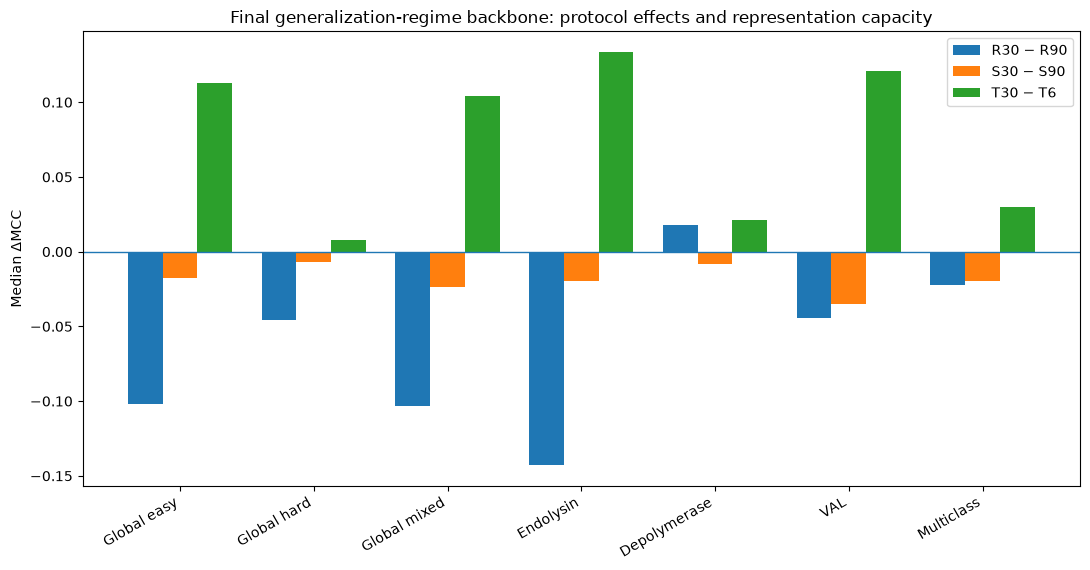

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_synthesis/rq25/figures/rq25_task_protocol_and_capacity_effects.png


In [18]:

# Figure 1 — task-level R, S, and T30 capacity effects.
plot = task_geometry.set_index("task").reindex(TASK_ORDER)

x = np.arange(len(plot))
w = 0.26

fig, ax = plt.subplots(figsize=(11.0, 5.8))
ax.bar(x - w, plot["median_R30_minus_R90"], width=w, label="R30 − R90")
ax.bar(x, plot["median_S30_minus_S90"], width=w, label="S30 − S90")
ax.bar(x + w, plot["median_T30_minus_T6"], width=w, label="T30 − T6")
ax.axhline(0, linewidth=1)
ax.set_xticks(x, [TASK_LABEL[t] for t in plot.index], rotation=30, ha="right")
ax.set_ylabel("Median ΔMCC")
ax.set_title("Final generalization-regime backbone: protocol effects and representation capacity")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq25_task_protocol_and_capacity_effects.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


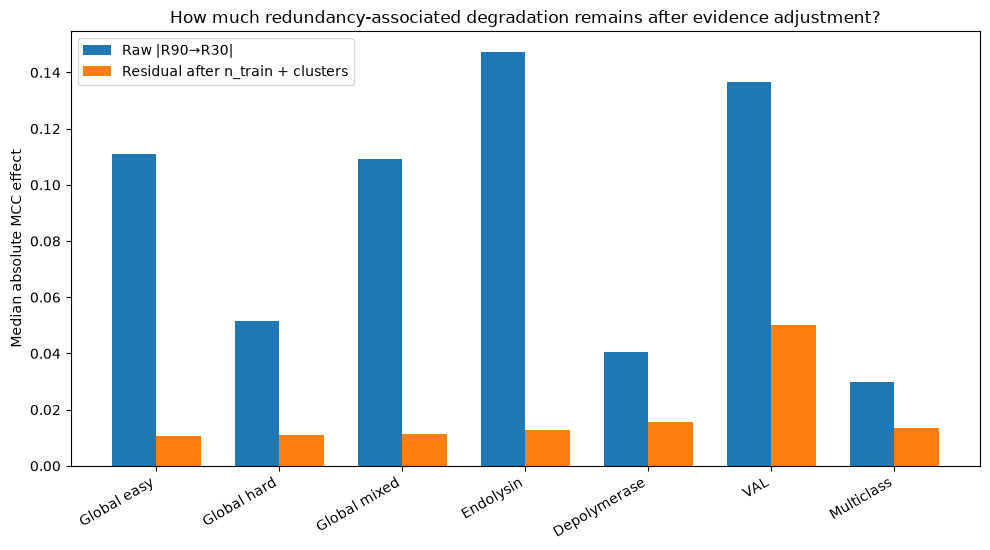

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_synthesis/rq25/figures/rq25_raw_vs_residual_R_by_task.png


In [19]:

# Figure 2 — raw versus evidence-adjusted R effect by task.
plot = residual_task.set_index("task").reindex(TASK_ORDER)

fig, ax = plt.subplots(figsize=(10.0, 5.6))
x = np.arange(len(plot))
w = 0.36

ax.bar(x - w/2, plot["median_raw_abs_R"], width=w, label="Raw |R90→R30|")
ax.bar(
    x + w/2,
    plot["median_QS_residual_abs_R"],
    width=w,
    label="Residual after n_train + clusters",
)
ax.set_xticks(x, [TASK_LABEL[t] for t in plot.index], rotation=30, ha="right")
ax.set_ylabel("Median absolute MCC effect")
ax.set_title("How much redundancy-associated degradation remains after evidence adjustment?")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq25_raw_vs_residual_R_by_task.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


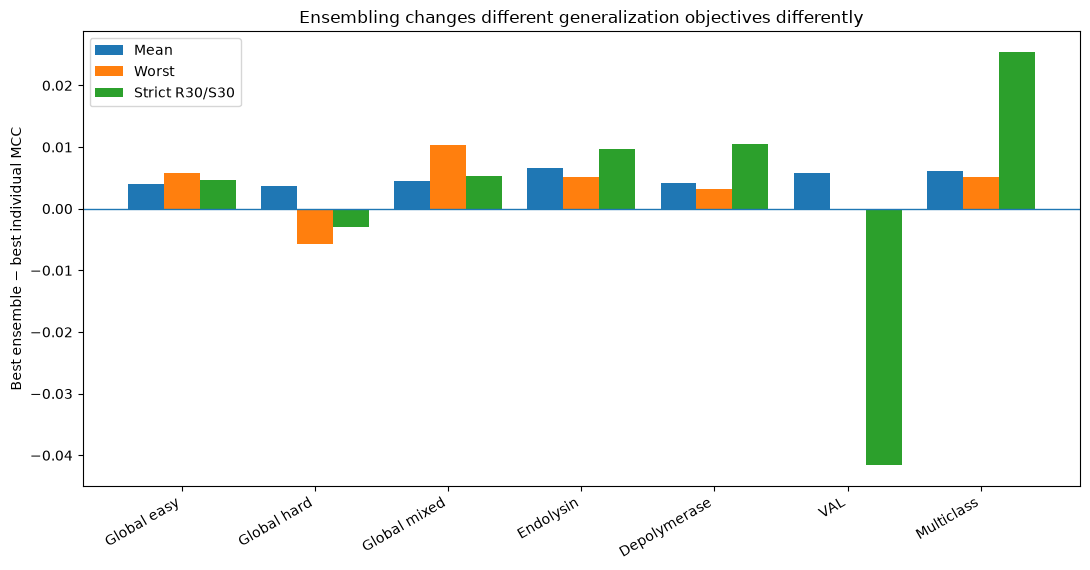

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_synthesis/rq25/figures/rq25_ensemble_gain_by_objective.png


In [20]:

# Figure 3 — ensemble consequences by endpoint.
plot = rq27_summary.set_index("task").reindex(TASK_ORDER)

x = np.arange(len(plot))
w = 0.27

fig, ax = plt.subplots(figsize=(11.0, 5.8))
ax.bar(x - w, plot["max_mean_gain_vs_best_single"], width=w, label="Mean")
ax.bar(x, plot["max_worst_gain_vs_best_single"], width=w, label="Worst")
ax.bar(x + w, plot["max_strict_gain_vs_best_single"], width=w, label="Strict R30/S30")
ax.axhline(0, linewidth=1)
ax.set_xticks(x, [TASK_LABEL[t] for t in plot.index], rotation=30, ha="right")
ax.set_ylabel("Best ensemble − best individual MCC")
ax.set_title("Ensembling changes different generalization objectives differently")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq25_ensemble_gain_by_objective.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


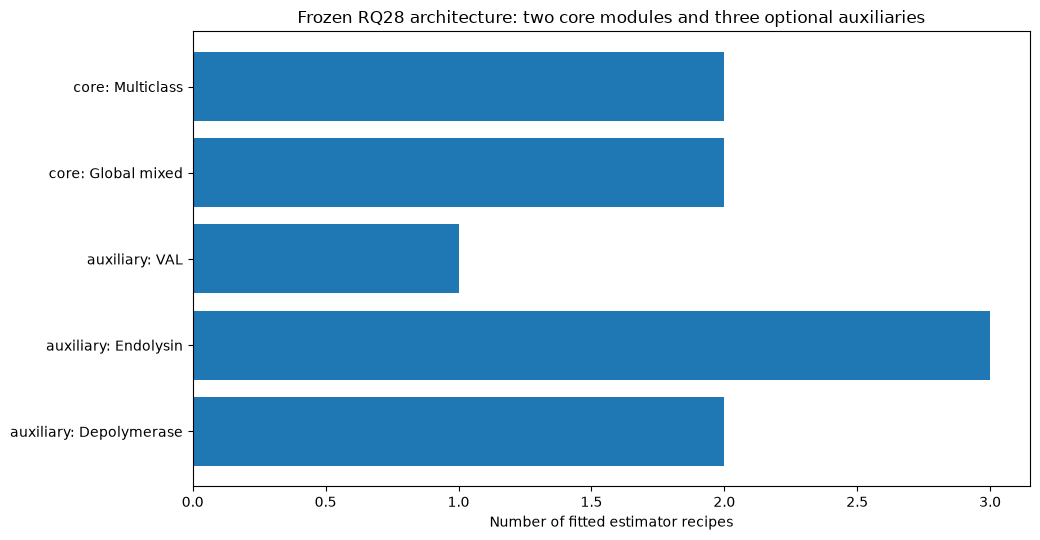

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_synthesis/rq25/figures/rq25_frozen_architecture_members.png


In [21]:

# Figure 4 — final production architecture membership.
plot = frozen_components.copy().sort_values(
    ["tier","default_execution","task"],
    ascending=[True,False,True],
)

fig, ax = plt.subplots(figsize=(10.5, 5.5))
y = np.arange(len(plot))
ax.barh(y, plot["n_members"])
ax.set_yticks(
    y,
    [
        f"{row.tier}: {TASK_LABEL.get(row.task, row.task)}"
        for row in plot.itertuples(index=False)
    ],
)
ax.set_xlabel("Number of fitted estimator recipes")
ax.set_title("Frozen RQ28 architecture: two core modules and three optional auxiliaries")
fig.tight_layout()

path = FIG_DIR / "rq25_frozen_architecture_members.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)



## 18. Final conceptual answer

The completed benchmark supports a **family of generalization regimes**, not one universal ranking.

The main synthesis is:

> **Generalization in phage lytic-function prediction emerges from the interaction between biological task formulation, redundancy-dependent evidence availability, train–test homology topology, representation capacity, and finite evidence support. Redundancy reduction is the dominant global protocol perturbation, but much of its observed penalty is statistically aligned with the amount and cluster structure of evidence removed. Homology separation changes mainly the topology of evaluation and has weaker, more irregular effects. Joint R×S difficulty is directional and frequently sub-additive, so no single strictness scalar or universal breakpoint captures the benchmark. Strong pretrained representations, especially ESM2-T30, provide the most transferable predictive foundation, whereas learner choice and ensembling contribute smaller, endpoint-specific gains. These regimes translate naturally into a hierarchical deployment architecture: one shared T30 representation, two core decisions, and three optional subtype-compatibility diagnostics.**

### Product-facing consequence

The benchmark does not justify deploying every benchmark task as a co-equal endpoint.

RQ28 freezes:

- `global_mixed` as the broad global lytic-recognition core;
- `multiclass_clean` as the primary functional-discrimination core;
- endolysin, depolymerase, and VAL binaries as optional compatibility diagnostics;
- unweighted soft voting where an ensemble is retained;
- ESM2-T30 as the shared representation for every frozen production recipe.

RQ29 remains responsible for the all-data production build and end-to-end inference validation.


## 19. Export canonical RQ25 artifacts

In [22]:

exports = {
    "rq25_preflight.tsv": preflight,
    "rq25_task_geometry.tsv": task_geometry,
    "rq25_robustness_synthesis.tsv": robustness_synthesis,
    "rq25_cross_strategy_robustness.tsv": cross_strategy,
    "rq25_supervised_stepwise_summary.tsv": sup_steps,
    "rq25_supervised_regime_composition.tsv": sup_regime_composition,
    "rq25_PU_stepwise_summary.tsv": pu_steps,
    "rq25_PU_regime_composition.tsv": pu_regime_composition,
    "rq25_joint_global_summary.tsv": joint_global,
    "rq25_joint_task_summary.tsv": joint_task,
    "rq25_evidence_mechanism_summary.tsv": evidence_mechanism_summary,
    "rq25_global_residual_R.tsv": global_residual_R,
    "rq25_residual_R_by_task.tsv": residual_task,
    "rq25_residual_R_by_representation.tsv": residual_rep,
    "rq25_uncertainty_backbone.tsv": uncertainty_backbone,
    "rq25_PU_strategy_summary.tsv": pu_strategy,
    "rq25_compute_strategy_summary.tsv": compute_strategy,
    "rq25_RQ26_portfolio_summary.tsv": rq26_portfolio_summary,
    "rq25_RQ27_ensemble_summary.tsv": rq27_summary,
    "rq25_RQ28_frozen_components.tsv": frozen_components,
    "rq25_final_regime_catalogue.tsv": catalogue,
    "rq25_mechanism_hierarchy.tsv": mechanism_hierarchy,
    "rq25_manuscript_claims.tsv": claims,
}

for filename, df in exports.items():
    path = RQ25_OUT / filename
    df.to_csv(path, sep="\t", index=False)
    print(f"Wrote {filename}: {len(df)} rows")

manifest = {
    "rq": "RQ25",
    "question": "what generalization regimes emerge from the complete benchmark?",
    "template_replaced": "20_RQ20_final_generalization_regime_synthesis_v2",
    "required_new_evidence": ["RQ6","RQ17","RQ20","RQ21","RQ22","RQ26","RQ27","RQ28"],
    "n_supervised_families": int(len(sup)),
    "n_supervised_surfaces": int(len(robust)),
    "n_tasks": int(catalogue["task"].nunique()),
    "n_RQ26_individual_candidates": int(len(topk)),
    "frozen_architecture_id": architecture_json["architecture_id"],
    "frozen_architecture_label": architecture_json["architecture_label"],
    "production_global_task": architecture_json["production_global_task"],
    "production_representation_convergence": (
        "ESM2-T30 only"
        if set(
            ";".join(frozen_components["member_representations"].astype(str))
            .split(";")
        ) == {"esm2_t30_150m"}
        else "mixed"
    ),
    "RQ29_required_for_scientific_RQ25_closure": False,
    "RQ29_next_step": "end-to-end production inference validation",
    "training_performed": False,
    "prediction_regeneration_performed": False,
    "bootstrap_performed": False,
    "deployment_reselection_performed": False,
}

with open(RQ25_OUT / "rq25_manifest.json", "w", encoding="utf-8") as fh:
    json.dump(manifest, fh, indent=2)

print("Wrote rq25_manifest.json")


Wrote rq25_preflight.tsv: 33 rows
Wrote rq25_task_geometry.tsv: 7 rows
Wrote rq25_robustness_synthesis.tsv: 7 rows
Wrote rq25_cross_strategy_robustness.tsv: 20 rows
Wrote rq25_supervised_stepwise_summary.tsv: 6 rows
Wrote rq25_supervised_regime_composition.tsv: 12 rows
Wrote rq25_PU_stepwise_summary.tsv: 6 rows
Wrote rq25_PU_regime_composition.tsv: 12 rows
Wrote rq25_joint_global_summary.tsv: 1 rows
Wrote rq25_joint_task_summary.tsv: 7 rows
Wrote rq25_evidence_mechanism_summary.tsv: 2 rows
Wrote rq25_global_residual_R.tsv: 1 rows
Wrote rq25_residual_R_by_task.tsv: 7 rows
Wrote rq25_residual_R_by_representation.tsv: 4 rows
Wrote rq25_uncertainty_backbone.tsv: 5 rows
Wrote rq25_PU_strategy_summary.tsv: 12 rows
Wrote rq25_compute_strategy_summary.tsv: 20 rows
Wrote rq25_RQ26_portfolio_summary.tsv: 7 rows
Wrote rq25_RQ27_ensemble_summary.tsv: 7 rows
Wrote rq25_RQ28_frozen_components.tsv: 5 rows
Wrote rq25_final_regime_catalogue.tsv: 7 rows
Wrote rq25_mechanism_hierarchy.tsv: 9 rows
Wrote r

## 20. Final closure gates

In [23]:

required_exports = [*exports.keys(), "rq25_manifest.json"]

assert len(sup) == 2240
assert len(rq6) == 2240
assert len(robust) == 140
assert len(joint) == 140
assert len(evidence) == 112
assert len(residual_surface) == 140

assert len(catalogue) == 7
assert set(catalogue["task"]) == set(TASK_ORDER)

assert len(topk) >= 14
assert len(frozen_components) == 5
assert frozen_components["tier"].eq("core").sum() == 2
assert frozen_components["tier"].eq("auxiliary").sum() == 3
assert architecture_json["architecture_id"] == "C_2_core_plus_3_aux"
assert architecture_json["production_global_task"] == "global_mixed"

# All frozen production recipes must converge to T30, as established by RQ28.
frozen_reps = set()
for value in frozen_components["member_representations"].astype(str):
    frozen_reps.update(x for x in value.split(";") if x)
assert frozen_reps == {T30}, frozen_reps

# Weighted production ensembles remain excluded.
assert not frozen_components["voting_scheme"].eq(
    "validation_weighted_soft"
).any()

# VAL remains auxiliary.
val_component = frozen_components[
    frozen_components["task"].eq("subtype_val")
]
assert len(val_component) == 1
assert val_component.iloc[0]["tier"] == "auxiliary"

assert all((RQ25_OUT / f).is_file() for f in required_exports)

figure_files = sorted(p.name for p in FIG_DIR.glob("*.png"))
assert len(figure_files) >= 4

print("RQ25_EXECUTION_GATES_OK")
print("Supervised families:", len(sup))
print("Complete R×S surfaces:", len(robust))
print("Tasks in final regime catalogue:", len(catalogue))
print("RQ26 individual candidates integrated:", len(topk))
print("Frozen architecture:", architecture_json["architecture_label"])
print("Production global task:", architecture_json["production_global_task"])
print("Frozen production representations:", sorted(frozen_reps))
print("Exports:", len(required_exports))
print("Figures:", figure_files)
print()
print(
    "Interpretation status: execution gates passed. "
    "Assign REAL-DATA PASS only after the executed real-project notebook is inspected "
    "for errors, stderr, quantitative coherence, and final claims."
)


RQ25_EXECUTION_GATES_OK
Supervised families: 2240
Complete R×S surfaces: 140
Tasks in final regime catalogue: 7
RQ26 individual candidates integrated: 23
Frozen architecture: 2 core + 3 auxiliary
Production global task: global_mixed
Frozen production representations: ['esm2_t30_150m']
Exports: 24
Figures: ['rq25_ensemble_gain_by_objective.png', 'rq25_frozen_architecture_members.png', 'rq25_raw_vs_residual_R_by_task.png', 'rq25_task_protocol_and_capacity_effects.png']

Interpretation status: execution gates passed. Assign REAL-DATA PASS only after the executed real-project notebook is inspected for errors, stderr, quantitative coherence, and final claims.
